# Отбор складов для дорожного графа
 Из выгрузки OSM получаем список самостоятельных складов и журнал решений по каждому объекту. Затем проверяем привязку складов к дорогам и строим дорожную часть графа по маршрутам между ними.


In [30]:
%pip install -q "osmnx>=2.1,<3" "scikit-learn>=1.4" "scipy>=1.12"
%pip install -q "folium>=0.17,<1"

In [2]:
# Параметры проверки
RUN_OSM = True
BBOX = (30.385, 59.795, 30.441, 59.824)
REGION_ID = "check-area"
CHECK_SITE_KEY = ("way", 1136945943)  # Площадка для разбора. None пропускает разбор.
TEST_PLACE = "Санкт-Петербург, Россия"
LIMIT = None                         # None использует весь подходящий набор.
ROAD_NETWORK_TYPE = "drive"
MAX_SNAP_DISTANCE_M = None            # Например, 100.0 для проверки порога в 100 м.
OSM_TIMEOUT_S = 60
OVERPASS_URLS = (
    "https://overpass-api.de/api",
    "https://overpass.private.coffee/api",
)

## 1. Правила отбора

| Решение | Правило |
|---|---|
| Включить | Есть `building=warehouse`, `building:use=warehouse` или `industrial=warehouse`, есть допустимая точка или полигон. Название может отсутствовать. |
| Проверить | Есть `industrial=logistics`, `amenity=warehouse` или складское название при общей разметке. Сюда же попадают явное противоречие в `building:use`, признаки заброшенности или отсутствие пригодной геометрии. |
| Исключить | Общая разметка `landuse=industrial`, `building=industrial`, `building=yes` или другие объекты без складских признаков. |


**Один комплекс — одна вершина.** Корпус относится к комплексу, если его геометрия целиком лежит в одной подходящей складской площадке, совпадает оператор или полное название, а сведения об операторах согласуются. При разных указанных операторах корпус остаётся отдельным объектом. При неоднозначной принадлежности корпуса оставляем самостоятельными кандидатами, а спорную площадку отправляем на проверку. Все OSM ID подтверждённых корпусов сохраняем у комплекса.


**Площадь и лимит.** Сравниваем площадь контура здания в м². Для комплекса суммируем известные площади его корпусов по уникальным OSM ID. Точки и площадки без известных контуров корпусов имеют неизвестную площадь. Сначала выделяем самостоятельные склады, затем применяем настраиваемый `limit`. `None` включает весь подходящий набор. При превышении лимита первыми идут склады с большей известной площадью. При равенстве учитываем наличие имени и оператора, затем OSM ID. Значения 250 и 500 предназначены для региональных замеров.


## 2. Реализация правил

`select_warehouses` получает записи с тегами, координатами, известной площадью и списком содержащих площадок. На выходе два списка — аргументы для `LogisticsNode` и журнал по OSM ID. В журнале видно, кто вошёл в отбор, кто объединён с площадкой, кому нужна проверка и кто оказался за лимитом.

In [3]:
"""Отбор самостоятельных складов для дорожного графа"""

from collections.abc import Iterable, Mapping
from dataclasses import dataclass
from math import isfinite
from numbers import Integral
from typing import TYPE_CHECKING

if TYPE_CHECKING:
    from geopandas import GeoDataFrame

WAREHOUSE_OSM_TAGS = {
    "building": ["warehouse"],
    "building:use": ["warehouse"],
    "industrial": ["warehouse", "logistics"],
    "amenity": ["warehouse"],
}

WAREHOUSE_TAGS = ("building:use", "building", "industrial")
TAGS_TO_KEEP = (*WAREHOUSE_TAGS, "landuse", "amenity", "name", "operator", "disused", "abandoned")
POLYGON_TYPES = {"Polygon", "MultiPolygon"}
WAREHOUSE_WORDS = ("склад", "логист", "распределительн", "warehouse", "logistics")


@dataclass(frozen=True)
class WarehouseInput:
    osm_id: str
    tags: Mapping[str, object]
    latitude: float | None
    longitude: float | None
    polygon_area_m2: float | None = None
    enclosing_site_ids: tuple[str, ...] = ()


def _text(tags: Mapping[str, object], key: str) -> str:
    value = tags.get(key)
    return value.strip() if isinstance(value, str) else ""


def _normalized(tags: Mapping[str, object], key: str) -> str:
    return " ".join(_text(tags, key).casefold().split())


def _classify(tags: Mapping[str, object]) -> tuple[str, str, str, list[str]]:
    matched = [f"{key}=warehouse" for key in WAREHOUSE_TAGS
               if _normalized(tags, key) == "warehouse"]
    if matched:
        use = _normalized(tags, "building:use")
        if use and use != "warehouse":
            return "review", "", "conflicting_building_use", matched + [f"building:use={use}"]
        if any(_normalized(tags, key) == "yes" for key in ("disused", "abandoned")):
            return "review", "", "inactive_object", matched
        kind = "building" if matched[0].startswith("building") else "site"
        return "eligible", kind, "warehouse_tag", matched

    if _normalized(tags, "industrial") == "logistics":
        return "review", "", "warehouse_use_to_check", ["industrial=logistics"]
    if _normalized(tags, "amenity") == "warehouse":
        return "review", "", "warehouse_use_to_check", ["amenity=warehouse"]
    name = _normalized(tags, "name")
    if any(word in name for word in WAREHOUSE_WORDS):
        return "review", "", "warehouse_word_in_name", []
    return "excluded", "", "no_warehouse_evidence", []


def _footprint(obj: WarehouseInput) -> float | None:
    area = obj.polygon_area_m2
    return area if area is not None and isfinite(area) and area > 0 else None


def select_warehouses(
    objects: Iterable[WarehouseInput],
    *,
    region_id: str = "custom",
    limit: int | None = None,
) -> tuple[list[dict], list[dict]]:
    """Вернуть аргументы для LogisticsNode и журнал решений по OSM ID."""
    if limit is not None:
        if isinstance(limit, bool) or not isinstance(limit, Integral) or limit < 1:
            raise ValueError("limit должен быть положительным целым числом или None")

    by_id = {}
    for obj in objects:
        by_id.setdefault(obj.osm_id, obj)

    audit = {}
    for osm_id, obj in by_id.items():
        decision, kind, reason, tags = _classify(obj.tags)
        if decision == "eligible":
            lat, lon = obj.latitude, obj.longitude
            if lat is None or lon is None or not (-90 <= lat <= 90 and -180 <= lon <= 180):
                decision, reason = "review", "missing_or_invalid_geometry"
        audit[osm_id] = {
            "osm_id": osm_id,
            "name": _text(obj.tags, "name"),
            "operator": _text(obj.tags, "operator"),
            "kind": kind,
            "decision": decision,
            "reason": reason,
            "matched_tags": tags,
            "source_tags": {
                key: value for key, value in obj.tags.items()
                if isinstance(value, str) and value.strip()
            },
            "parent_osm_id": None,
            "warehouse_area_m2": _footprint(obj) if kind == "building" else None,
        }

    # Вложенность и подтверждение принадлежности проверяются до лимита.
    proposed_parents = {}
    ambiguous_sites = set()
    for osm_id, obj in by_id.items():
        if audit[osm_id]["decision"] != "eligible" or audit[osm_id]["kind"] != "building":
            continue
        plausible_sites = []
        matching_sites = []
        child_operator = _normalized(obj.tags, "operator")
        child_name = _normalized(obj.tags, "name")

        for site_id in set(obj.enclosing_site_ids):
            site = audit.get(site_id)
            if not site or site["decision"] != "eligible" or site["kind"] != "site":
                continue
            site_tags = by_id[site_id].tags
            site_operator = _normalized(site_tags, "operator")
            if child_operator and site_operator and child_operator != site_operator:
                continue
            plausible_sites.append(site_id)
            same_operator = child_operator and child_operator == site_operator
            same_name = child_name and child_name == _normalized(site_tags, "name")
            if same_operator or same_name:
                matching_sites.append(site_id)

        if len(plausible_sites) == 1 and matching_sites:
            proposed_parents[osm_id] = matching_sites[0]
        else:
            ambiguous_sites.update(plausible_sites)

    for site_id in ambiguous_sites:
        audit[site_id].update(decision="review", reason="ambiguous_complex_membership")

    members = {}
    for building_id, site_id in proposed_parents.items():
        if site_id in ambiguous_sites:
            continue
        audit[building_id].update(
            decision="grouped", reason="same_complex", parent_osm_id=site_id,
        )
        members.setdefault(site_id, []).append(building_id)

    for site_id, child_ids in members.items():
        areas = [_footprint(by_id[child_id]) for child_id in child_ids]
        known_areas = [area for area in areas if area is not None]
        if known_areas:
            audit[site_id]["warehouse_area_m2"] = sum(known_areas)

    ready = sorted(osm_id for osm_id, row in audit.items() if row["decision"] == "eligible")
    if limit is not None and len(ready) > limit:
        def priority(osm_id):
            row = audit[osm_id]
            area = row["warehouse_area_m2"]
            info_count = bool(row["name"]) + bool(row["operator"])
            return area is None, -(area or 0), -info_count, osm_id

        ready.sort(key=priority)
        for osm_id in ready[limit:]:
            audit[osm_id].update(decision="over_limit", reason="selection_limit")
        ready = ready[:limit]

    selected = []
    for osm_id in ready:
        obj, row = by_id[osm_id], audit[osm_id]
        row["decision"] = "selected"
        source_ids = [osm_id, *sorted(members.get(osm_id, []))]
        node_id = "warehouse_" + osm_id.replace(":", "_").replace("/", "_")
        label = "Складской комплекс" if row["kind"] == "site" else "Склад"
        selected.append({
            "id": node_id,
            "name": row["name"] or f"{label} ({osm_id})",
            "object_type": "warehouse",
            "latitude": obj.latitude,
            "longitude": obj.longitude,
            "region_ids": [region_id],
            "source_osm_ids": source_ids,
            "verification_status": "candidate",
            "transport_modes": ["road"],
            "graph_role": "node_candidate",
            "identification_basis": {
                "matched_tag": row["matched_tags"][0],
                "matched_tags": row["matched_tags"],
                "tag_strength": "strong",
                "warehouse_kind": row["kind"],
                "warehouse_area_m2": row["warehouse_area_m2"],
                "operator": row["operator"] or None,
            },
        })

    return selected, [audit[osm_id] for osm_id in sorted(audit)]

## 3. Контрольный пример без OSM

Тестовые записи специально покрывают два корпуса одного оператора, независимый склад в той же границе, площадку с неясной принадлежностью и здание без складской функции. Списки содержащих площадок здесь заданы вручную. Для выгрузки OSM их рассчитывает адаптер ниже.

In [4]:
import pandas as pd

site_a = "osm:relation/100"
site_b = "osm:relation/200"
example = [
    WarehouseInput(site_a, {"industrial": "warehouse", "name": "Комплекс Север",
                            "operator": "Север"}, 59.90, 30.30, 25000),
    WarehouseInput("osm:way/101", {"building": "warehouse", "name": "Корпус 1",
                                 "operator": "Север"}, 59.901, 30.30, 2500, (site_a,)),
    WarehouseInput("osm:way/102", {"building": "warehouse", "name": "Корпус 2",
                                 "operator": " север "}, 59.902, 30.30, 1500, (site_a,)),
    WarehouseInput("osm:way/103", {"building": "warehouse", "name": "Склад Восток",
                                 "operator": "Восток"}, 59.903, 30.30, 1800, (site_a,)),
    WarehouseInput("osm:way/104", {"building": "warehouse"}, 59.91, 30.32, 6500),
    WarehouseInput("osm:node/104", {"industrial": "warehouse"}, 59.92, 30.33),
    WarehouseInput(site_b, {"industrial": "warehouse", "name": "Площадка Б"}, 59.93, 30.34),
    WarehouseInput("osm:way/201", {"building": "warehouse", "name": "Склад 201"},
                   59.931, 30.34, 2300, (site_b,)),
    WarehouseInput("osm:way/300", {"building": "industrial", "name": "Цех"}, 59.94, 30.35),
    WarehouseInput("osm:way/301", {"landuse": "industrial", "name": "Промзона"}, 59.95, 30.36),
    WarehouseInput("osm:way/302", {"building": "warehouse", "building:use": "office"},
                   59.96, 30.37),
    WarehouseInput("osm:way/303", {"industrial": "logistics", "name": "Логопарк"},
                   59.97, 30.38),
    WarehouseInput("osm:way/304", {"building": "yes", "building:use": "warehouse"},
                   59.98, 30.39, 3100),
    WarehouseInput("osm:way/305", {"building": "yes", "name": "Склад у станции"},
                   59.99, 30.40),
    WarehouseInput("osm:way/306", {"building": "warehouse"}, None, None),
]

selected, audit = select_warehouses(example, region_id="check")
by_osm_id = {row["osm_id"]: row for row in audit}
site_record = next(row for row in selected if row["source_osm_ids"][0] == site_a)

assert len(selected) == 6
assert site_record["source_osm_ids"] == [site_a, "osm:way/101", "osm:way/102"]
assert site_record["identification_basis"]["warehouse_area_m2"] == 4000
assert by_osm_id["osm:way/103"]["decision"] == "selected"
assert by_osm_id[site_b]["decision"] == "review"
assert by_osm_id["osm:way/201"]["decision"] == "selected"
assert by_osm_id["osm:way/300"]["decision"] == "excluded"
assert by_osm_id["osm:way/302"]["decision"] == "review"
assert by_osm_id["osm:node/104"]["warehouse_area_m2"] is None

limited, limited_audit = select_warehouses(example, region_id="check", limit=2)
assert [record["source_osm_ids"][0] for record in limited] == ["osm:way/104", site_a]
assert sum(row["decision"] == "over_limit" for row in limited_audit) == 4

columns = ["osm_id", "name", "decision", "reason", "warehouse_area_m2", "parent_osm_id"]
display(pd.DataFrame(audit)[columns].fillna("—"))
print("Контрольный пример прошёл проверки. Отобрано складов:", len(selected))

,osm_id,name,decision,reason,warehouse_area_m2,parent_osm_id
0,osm:node/104,,selected,warehouse_tag,—,—
1,osm:relation/100,Комплекс Север,selected,warehouse_tag,4000.0,—
2,osm:relation/200,Площадка Б,review,ambiguous_complex_membership,—,—
3,osm:way/101,Корпус 1,grouped,same_complex,2500.0,osm:relation/100
4,osm:way/102,Корпус 2,grouped,same_complex,1500.0,osm:relation/100
5,osm:way/103,Склад Восток,selected,warehouse_tag,1800.0,—
6,osm:way/104,,selected,warehouse_tag,6500.0,—
7,osm:way/201,Склад 201,selected,warehouse_tag,2300.0,—
8,osm:way/300,Цех,excluded,no_warehouse_evidence,—,—
9,osm:way/301,Промзона,excluded,no_warehouse_evidence,—,—


Контрольный пример прошёл проверки. Отобрано складов: 6


### Проверяем лимит

На искусственном наборе из 520 отдельных складов проверяем, что `None` сохраняет все записи, а выборки в 250 и 500 формируются из одного набора. Число направлений показывает размер будущего перебора пар.

In [16]:
many = [
    WarehouseInput(f"osm:way/{1000 + i}", {"building": "warehouse"},
                   59.9, 30.3, 100 + i)
    for i in range(520)
]
sizes = []
for current_limit in (None, 250, 500):
    sample, sample_audit = select_warehouses(many, limit=current_limit)
    n = len(sample)
    assert n == (len(many) if current_limit is None else current_limit)
    if current_limit is not None:
        assert sample[0]["source_osm_ids"] == ["osm:way/1519"]
    sizes.append({
        "лимит": "весь набор" if current_limit is None else str(current_limit),
        "складов": n,
        "за лимитом": sum(row["decision"] == "over_limit" for row in sample_audit),
        "возможных направлений": n * (n - 1),
    })
display(pd.DataFrame(sizes))

,лимит,складов,за лимитом,возможных направлений
0,весь набор,520,0,269880
1,250,250,270,62250
2,500,500,20,249500


## 4. Адаптер для выгрузки OSMnx

На вход подаём `GeoDataFrame` с индексом `(тип элемента, OSM ID)` и указанной системой координат. Адаптер находит полное вхождение корпусов в площадки через пространственное соединение и считает площадь контуров в равновеликой проекции `EPSG:6933`. Координаты вершины берёт из внутренней точки в `EPSG:4326`.

In [5]:
def select_warehouses_from_gdf(
    features: "GeoDataFrame",
    *,
    region_id: str = "custom",
    limit: int | None = None,
) -> tuple[list[dict], list[dict]]:
    """Преобразовать исходную выгрузку OSMnx и применить правила отбора."""
    if features.empty:
        return select_warehouses([], region_id=region_id, limit=limit)

    import geopandas as gpd

    if features.crs is None:
        raise ValueError("У входного GeoDataFrame должна быть задана CRS")
    if features.index.nlevels != 2:
        raise ValueError("Ожидается индекс OSMnx (тип элемента, OSM ID)")

    work = features.loc[~features.index.duplicated()].to_crs("EPSG:4326")
    work.index = [f"osm:{element}/{osm_id}" for element, osm_id in work.index]
    geometry_column = work.geometry.name
    geometry = work.geometry
    valid = geometry.is_valid & ~geometry.is_empty
    polygons = valid & geometry.geom_type.isin(POLYGON_TYPES)
    supported = polygons | (valid & geometry.geom_type.eq("Point"))

    tag_rows = work.reindex(columns=TAGS_TO_KEEP).to_dict(orient="index")
    decisions = {osm_id: _classify(tags) for osm_id, tags in tag_rows.items()}
    buildings = [osm_id for osm_id, (decision, kind, _, _) in decisions.items()
                 if decision == "eligible" and kind == "building" and supported.loc[osm_id]]
    sites = [osm_id for osm_id, (decision, kind, _, _) in decisions.items()
             if decision == "eligible" and kind == "site" and polygons.loc[osm_id]]
    footprints = geometry.loc[[osm_id for osm_id in buildings if polygons.loc[osm_id]]]
    areas = footprints.to_crs("EPSG:6933").area.to_dict() if len(footprints) else {}

    enclosing = {}
    if buildings and sites:
        site_shapes = work.loc[sites, [geometry_column]].assign(site_osm_id=sites)
        matches = gpd.sjoin(
            work.loc[buildings, [geometry_column]],
            site_shapes,
            how="inner",
            predicate="covered_by",
        )
        enclosing = matches.groupby(level=0)["site_osm_id"].agg(tuple).to_dict()

    objects = []
    for osm_id, tags in tag_rows.items():
        point = geometry.loc[osm_id].representative_point() if supported.loc[osm_id] else None
        objects.append(WarehouseInput(
            osm_id=osm_id,
            tags=tags,
            latitude=float(point.y) if point is not None else None,
            longitude=float(point.x) if point is not None else None,
            polygon_area_m2=areas.get(osm_id),
            enclosing_site_ids=enclosing.get(osm_id, ()),
        ))

    return select_warehouses(objects, region_id=region_id, limit=limit)

In [6]:
from importlib.util import find_spec
from math import isclose

if find_spec("geopandas") is None:
    print("Геометрический пример доступен в ядре с GeoPandas.")
else:
    import geopandas as gpd
    from shapely.geometry import Point, box

    x, y = 2_890_000, 6_350_000
    geo_example = gpd.GeoDataFrame(
        [
            {"industrial": "warehouse", "name": "Тестовая площадка", "operator": "А"},
            {"building": "warehouse", "name": "Корпус", "operator": "А"},
            {"building": "warehouse", "name": "Отдельная точка"},
            {"building": "warehouse", "name": "Геометрия отсутствует"},
        ],
        geometry=[
            box(x, y, x + 240, y + 180),
            box(x + 20, y + 20, x + 60, y + 50),
            Point(x + 300, y + 200),
            None,
        ],
        crs="EPSG:6933",
        index=pd.MultiIndex.from_tuples(
            [("relation", 700), ("way", 701), ("node", 702), ("way", 703)],
            names=["element", "id"],
        ),
    )
    geo_selected, geo_audit = select_warehouses_from_gdf(geo_example)
    complex_row = next(row for row in geo_selected
                       if row["source_osm_ids"][0] == "osm:relation/700")
    assert len(geo_selected) == 2
    assert complex_row["source_osm_ids"] == ["osm:relation/700", "osm:way/701"]
    assert isclose(complex_row["identification_basis"]["warehouse_area_m2"],
                   1200, rel_tol=1e-5)
    assert next(row for row in geo_audit
                if row["osm_id"] == "osm:way/703")["decision"] == "review"
    print("Геометрический пример прошёл. Площадь корпуса округлённо 1 200 м².")

Геометрический пример прошёл. Площадь корпуса округлённо 1 200 м².


## 5. Проверка на выбранной области

`BBOX` задаёт прямоугольник в порядке `(запад, юг, восток, север)`. Начальный пример — участок в Шушарах.

 `TEST_PLACE` задаёт территорию для отдельного регионального замера ниже. Значение `None` позволяет пропустить соответствующий пример.

OSMnx сохраняет ответы в кэше текущей среды выполнения. При ошибке запроса к Overpass ноутбук пробует резервный сервер и выводит причину сбоя. Зависимые шаги пропускаются с пояснением. После временного сбоя запускаем ячейку загрузки и следующие за ней ячейки.


In [7]:
from collections import Counter
from time import perf_counter, sleep

if RUN_OSM:
    import networkx as nx
    import osmnx as ox
    from osmnx._errors import InsufficientResponseError, ResponseStatusCodeError
    from requests.exceptions import RequestException

    ox.settings.use_cache = True


def _raise_http_error(response, *args, **kwargs):
    # Передаём HTTP-ошибки в наш цикл, включая 429 и 504,
    # для которых OSMnx иначе сам повторяет запрос.
    response.raise_for_status()


def load_osm(label, loader, *args, overpass=True, **kwargs):
    """Загрузить данные OSM или вернуть None после ошибок источника."""
    urls = OVERPASS_URLS if overpass else (ox.settings.nominatim_url,)
    settings = ox.settings
    original_url = settings.overpass_url
    original_timeout = settings.requests_timeout
    original_kwargs = settings.requests_kwargs
    try:
        settings.requests_timeout = OSM_TIMEOUT_S
        settings.requests_kwargs = {
            **original_kwargs,
            "hooks": {"response": _raise_http_error},
        }
        for attempt, url in enumerate(urls):
            if attempt:
                print("Повтор через 10 с на резервном сервере.", flush=True)
                sleep(10)
            if overpass:
                settings.overpass_url = url
            print(f"{label} — {url}", flush=True)
            try:
                return loader(*args, **kwargs)
            except (RequestException, ResponseStatusCodeError, InsufficientResponseError) as error:
                detail = str(error).split("\n", 1)[0]
                print(f"{type(error).__name__} — {detail[:220]}", flush=True)
    finally:
        settings.overpass_url = original_url
        settings.requests_timeout = original_timeout
        settings.requests_kwargs = original_kwargs

    print(f"{label} — данные не получены. Эту ячейку можно запустить повторно.")
    return None

In [8]:
osm_features = None
osm_selected, osm_audit = [], []
control_features = control_report = added = None

if not RUN_OSM or BBOX is None:
    print("Проверка области через OSM пропущена. Проверь RUN_OSM и BBOX.")
else:
    west, south, east, north = BBOX
    if not (-180 <= west < east <= 180 and -90 <= south < north <= 90):
        raise ValueError("Укажи границы в порядке west, south, east, north")

    osm_features = load_osm(
        "Загружаем складские объекты", ox.features_from_bbox, BBOX,
        tags=WAREHOUSE_OSM_TAGS,
    )
    if osm_features is not None:
        osm_selected, osm_audit = select_warehouses_from_gdf(
            osm_features, region_id=REGION_ID, limit=LIMIT,
        )
        print("OSM-объектов", len(osm_features), "| Складов в расчёте", len(osm_selected))
        if osm_audit:
            report = pd.DataFrame(osm_audit)
            display(report["decision"].value_counts().rename("число объектов"))
            display(report[columns].head(30).fillna("—"))

Загружаем складские объекты — https://overpass-api.de/api
OSM-объектов 15 | Складов в расчёте 14


,число объектов
decision,
selected,14
review,1


,osm_id,name,decision,reason,warehouse_area_m2,parent_osm_id
0,osm:node/10844030702,Хранилкин.рф,selected,warehouse_tag,—,—
1,osm:way/1136945943,,review,ambiguous_complex_membership,—,—
2,osm:way/1176872959,,selected,warehouse_tag,97371.912336,—
3,osm:way/1368691811,,selected,warehouse_tag,25248.846493,—
4,osm:way/1368691812,,selected,warehouse_tag,5157.273412,—
5,osm:way/1368691813,,selected,warehouse_tag,5157.359629,—
6,osm:way/423843614,,selected,warehouse_tag,27158.619246,—
7,osm:way/78401306,,selected,warehouse_tag,33861.767642,—
8,osm:way/78401309,,selected,warehouse_tag,1175.425801,—
9,osm:way/78401313,,selected,warehouse_tag,13229.348174,—


### 5.1. Проверка площадки и её корпусов

`CHECK_SITE_KEY` задаёт пример площадки для разбора. В таблице показаны теги и решения для неё и объектов внутри контура. При смене области можно выбрать другой OSM ID.

В сохранённом замере по Шушарам из 15 OSM-объектов отобрали 14 складов. Площадку `osm:way/1136945943` оставили на проверку из-за неясной принадлежности корпуса.

,kind,name,operator,decision,source_tags
osm_id,,,,,
osm:way/1136945943,site,—,—,review,"{'industrial': 'warehouse', 'landuse': 'indust..."
osm:way/1176872959,building,—,—,selected,{'building': 'warehouse'}


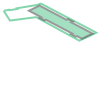

In [9]:
if osm_features is None or CHECK_SITE_KEY is None:
    print("Разбор площадки пропущен. Нужна выгрузка объектов и OSM ID площадки.")
elif CHECK_SITE_KEY not in osm_features.index:
    print(f"Площадка {CHECK_SITE_KEY} отсутствует в этой выгрузке.")
else:
    from shapely.geometry import GeometryCollection

    site_features = osm_features.loc[~osm_features.index.duplicated()]
    site_geometry = site_features.geometry.loc[CHECK_SITE_KEY]
    if site_geometry is None or not site_geometry.is_valid or site_geometry.is_empty:
        print("Геометрию площадки нужно проверить.")
    else:
        inside = site_features.loc[site_features.geometry.covered_by(site_geometry)]
        inside_ids = [f"osm:{element}/{osm_id}" for element, osm_id in inside.index]
        audit_by_id = pd.DataFrame(osm_audit).set_index("osm_id")
        columns_to_check = ["kind", "name", "operator", "decision", "source_tags"]
        display(audit_by_id.loc[inside_ids, columns_to_check].replace("", "—"))

        inner_geometries = inside.geometry.drop(index=CHECK_SITE_KEY)
        display(GeometryCollection([site_geometry.boundary, *inner_geometries]))

### 5.2. Расширенная выборка и тест лимита

Добавляем общие промышленные теги, чтобы проверить объекты, у которых складская функция видна только из названия. Сравниваем с основной выборкой и разбираем пересечения с уже отобранными складами. Последняя ячейка показывает порядок отбора при тестовом лимите в пять объектов.

В сохранённом замере расширение выборки дало два объекта на проверку по названию. Распределительный центр «Пятерочка» содержал размеченный склад `osm:way/423843614`. У комплекса Wurth было ноль пересечений с отобранными складами.

In [11]:
control_features = control_report = added = None
if osm_features is None:
    print("Для сравнения сначала загрузи складские объекты в выбранной области.")
else:
    control_tags = {
        **WAREHOUSE_OSM_TAGS,
        "building": ["warehouse", "industrial", "yes"],
        "landuse": ["industrial"],
    }
    control_features = load_osm(
        "Загружаем расширенную выборку", ox.features_from_bbox, BBOX, tags=control_tags,
    )
    if control_features is not None:
        control_selected, control_audit = select_warehouses_from_gdf(
            control_features, region_id=REGION_ID, limit=LIMIT,
        )
        print(f"Складских вершин до и после расширения — {len(osm_selected)} → {len(control_selected)}")
        if control_audit:
            control_report = pd.DataFrame(control_audit)
            base_ids = {row["osm_id"] for row in osm_audit}
            added = control_report.loc[~control_report["osm_id"].isin(base_ids)]
            display(added.groupby(["decision", "reason"]).size().rename("объектов").to_frame())
            display(added.loc[
                added["decision"].isin(["review", "selected"]),
                ["osm_id", "name", "decision", "reason"],
            ].head(10))

Загружаем расширенную выборку — https://overpass-api.de/api
Складских вершин до и после расширения — 14 → 14


,,объектов
decision,reason,
excluded,no_warehouse_evidence,339
review,warehouse_word_in_name,2


,osm_id,name,decision,reason
13,osm:relation/6950685,Распределительный центр «Пятерочка»,review,warehouse_word_in_name
216,osm:way/242852422,Производственно-складской комплекс Wurth,review,warehouse_word_in_name


In [12]:
if added is None:
    print("Разбор кандидатов пропущен. Нужна расширенная выгрузка.")
else:
    features_by_id = control_features.loc[~control_features.index.duplicated()].copy()
    features_by_id.index = [
        f"osm:{element}/{osm_id}" for element, osm_id in features_by_id.index
    ]
    candidate_ids = added.loc[added["reason"].eq("warehouse_word_in_name"), "osm_id"]
    selected_ids = control_report.loc[control_report["decision"].eq("selected"), "osm_id"]
    selected_geometries = features_by_id.geometry.loc[selected_ids]

    if candidate_ids.empty:
        print("В расширенной выборке нет новых кандидатов со складским названием.")
    for osm_id in candidate_ids:
        feature = features_by_id.loc[osm_id]
        geometry = features_by_id.geometry.loc[osm_id]

        print(f"\n{osm_id} — {feature['name']}")
        display(feature.drop(labels=features_by_id.geometry.name).dropna().to_frame("значение"))

        if geometry is None or geometry.is_empty or not geometry.is_valid:
            print("Геометрию нужно проверить.")
            continue

        overlaps = selected_geometries[selected_geometries.intersects(geometry)]
        print(f"Геометрия — {geometry.geom_type}. Пересечений со складами — {len(overlaps)}")
        if not overlaps.empty:
            display(pd.DataFrame({
                "склад целиком внутри кандидата": overlaps.covered_by(geometry),
                "кандидат целиком внутри склада": overlaps.covers(geometry),
            }))


osm:relation/6950685 — Распределительный центр «Пятерочка»


,значение
name,Распределительный центр «Пятерочка»
landuse,industrial
type,multipolygon
fixme,Уточнить границы/название и пр детали


Геометрия — Polygon. Пересечений со складами — 1


,склад целиком внутри кандидата,кандидат целиком внутри склада
osm:way/423843614,True,False



osm:way/242852422 — Производственно-складской комплекс Wurth


,значение
name,Производственно-складской комплекс Wurth
operator,"ЗАО ""Вюрт Северо-Запад"""
landuse,industrial


Геометрия — Polygon. Пересечений со складами — 0


In [13]:
if control_report is None:
    print("Проверка ранжирования пропущена. Нужна расширенная выгрузка.")
else:
    test_limit = 5

    _, limited_audit = select_warehouses_from_gdf(
        control_features, limit=test_limit
    )
    limited_report = pd.DataFrame(limited_audit)

    ranking = limited_report.loc[
        limited_report["decision"].isin(["selected", "over_limit"])
    ].copy()
    ranking["filled_fields"] = ranking[["name", "operator"]].ne("").sum(axis=1)

    ranking = ranking.sort_values(
        ["warehouse_area_m2", "filled_fields", "osm_id"],
        ascending=[False, False, True],
        na_position="last",
    )

    display(ranking[
        ["osm_id", "name", "warehouse_area_m2", "filled_fields", "decision"]
    ])

,osm_id,name,warehouse_area_m2,filled_fields,decision
43,osm:way/1176872959,,97371.912336,0,selected
321,osm:way/78697315,"Логистический терминал ""PNK""",36676.045172,1,selected
299,osm:way/78401306,,33861.767642,0,selected
322,osm:way/78697316,,30630.931861,0,selected
249,osm:way/423843614,,27158.619246,0,selected
104,osm:way/1368691811,,25248.846493,0,over_limit
302,osm:way/78401313,,13229.348174,1,over_limit
319,osm:way/78697309,,11086.845311,0,over_limit
348,osm:way/813195812,,5157.442450,0,over_limit
106,osm:way/1368691813,,5157.359629,0,over_limit


## Правила отбора складов для дорожного графа

1. **Автоматический отбор.** В выбранной области берём объекты с
   `building=warehouse`, `building:use=warehouse` или `industrial=warehouse`.
   Подходит валидная точка, полигон или мультиполигон. Название и оператор
   могут быть пустыми.

2. **Проверка спорных объектов.** Признак склада только в названии,
   `industrial=logistics` или `amenity=warehouse` дают статус `review`.
   Туда же отправляем складские объекты с конфликтом назначения, признаком
   неактивности или непригодной геометрией. Промышленные объекты без
   складских признаков получают `excluded`. Объекты со складом только
   в названии проверяем на расширенной выгрузке.

3. **Одна вершина на подтверждённый комплекс.** Объединяем корпус с площадкой,
   если он целиком внутри единственной подходящей площадки и совпадает
   оператор или полное название. Если у обоих указаны разные операторы,
   объекты рассматриваем отдельно. При неясной принадлежности размеченные
   корпуса оставляем отдельными, а площадку отправляем в `review`.

4. **Площадь.** Для корпуса берём площадь его контура в м², для комплекса —
   сумму известных площадей подтверждённых корпусов. У точки площадь
   остаётся неизвестной. Минимальную площадь для отбора не задаём.

5. **Лимит.** Применяем его после группировки. При `limit=None` берём все
   прошедшие отбор объекты. При превышении лимита сначала идут склады
   с известной площадью по убыванию, затем склады с неизвестной площадью.
   При равной площади или если она неизвестна у обоих, выше склад с большим
   числом заполненных полей `name` и `operator`. Последний критерий —
   порядок OSM ID. Склад за границей лимита получает `over_limit`.

Выбранные складские вершины передаём на привязку к дорогам.
По каждому OSM ID сохраняем решение и его причину в журнале отбора.

## 6. Региональная проверка

Загружаем границу `TEST_PLACE`, складские объекты и автомобильные дороги. Для быстрого первого запуска можно указать небольшую территорию. Затем сравниваем простой поиск от ближайших дорожных узлов с привязкой из проекта.

In [15]:
region_boundary = region_features = region_roads = None
region_warehouses, region_audit, warehouse_nodes = [], [], []
snapped_warehouses = None

if not RUN_OSM or TEST_PLACE is None:
    print("Региональная проверка пропущена. Проверь RUN_OSM и TEST_PLACE.")
else:
    territory = load_osm(
        "Ищем границу региона", ox.geocode_to_gdf, TEST_PLACE, overpass=False,
    )
    if territory is not None and not territory.empty:
        boundary = territory.geometry.iloc[0]
        if (boundary is not None and boundary.geom_type in POLYGON_TYPES
                and boundary.is_valid and not boundary.is_empty):
            region_boundary = boundary
            region_features = load_osm(
                "Загружаем склады региона", ox.features_from_polygon, region_boundary,
                tags=WAREHOUSE_OSM_TAGS,
            )
        else:
            print(f"Для {TEST_PLACE!r} нужна валидная полигональная граница.")

    if region_features is not None:
        region_warehouses, region_audit = select_warehouses_from_gdf(
            region_features, region_id="regional-check", limit=LIMIT,
        )
        total = sum(row["decision"] in {"selected", "over_limit"} for row in region_audit)
        scenarios = [(f"Лимит {n}", n) for n in (250, 500) if n < total]
        scenarios.append(("Все склады", total))
        display(pd.DataFrame([
            {"режим": label, "складов": n, "направлений для проверки": n * (n - 1)}
            for label, n in scenarios
        ]))
        print(f"Складов для текущего расчёта — {len(region_warehouses)}")

Ищем границу региона — https://nominatim.openstreetmap.org/
Загружаем склады региона — https://overpass-api.de/api


,режим,складов,направлений для проверки
0,Лимит 250,250,62250
1,Лимит 500,500,249500
2,Все склады,632,398792


Складов для текущего расчёта — 632


In [20]:
region_roads = None
warehouse_nodes = []
snapped_warehouses = None

if region_boundary is None or not region_warehouses:
    print("Загрузка дорог пропущена. Нужны граница региона и отобранные склады.")
else:
    region_roads = load_osm(
        "Загружаем автомобильные дороги", ox.graph_from_polygon, region_boundary,
        network_type=ROAD_NETWORK_TYPE, retain_all=True,
    )
    if region_roads is not None and region_roads.number_of_nodes() > 0:
        print(f"Дорожный граф готов. Узлов — {region_roads.number_of_nodes()}")
    elif region_roads is not None:
        region_roads = None
        print("В выгрузке дорожной сети нет узлов.")

Загружаем автомобильные дороги — https://overpass-api.de/api
Дорожный граф готов. Узлов — 18686


In [21]:
from random import Random

warehouse_nodes = []
if region_roads is None:
    print("Замер пропущен. Сначала загрузи дорожный граф.")
else:
    warehouse_nodes = list(ox.distance.nearest_nodes(
        region_roads,
        X=[warehouse["longitude"] for warehouse in region_warehouses],
        Y=[warehouse["latitude"] for warehouse in region_warehouses],
    ))
    unique_nodes = list(dict.fromkeys(warehouse_nodes))

    if len(unique_nodes) < 2:
        print("Для замера нужны хотя бы две разные точки привязки.")
    else:
        rng = Random(64)
        probe_pairs = [rng.sample(unique_nodes, 2) for _ in range(20)]
        probe_sources = rng.sample(unique_nodes, min(5, len(unique_nodes)))

        started = perf_counter()
        for source, target in probe_pairs:
            try:
                nx.shortest_path_length(region_roads, source, target, weight="length")
                nx.shortest_path(region_roads, source, target, weight="length")
            except nx.NetworkXNoPath:
                continue
        pair_seconds = (perf_counter() - started) / len(probe_pairs)

        started = perf_counter()
        for source in probe_sources:
            nx.dijkstra_predecessor_and_distance(region_roads, source, weight="length")
        source_seconds = (perf_counter() - started) / len(probe_sources)

        n = len(warehouse_nodes)
        benchmark = pd.DataFrame({
            "способ": ["Отдельно по направлениям", "От каждого узла привязки"],
            "пробных запусков": [len(probe_pairs), len(probe_sources)],
            "среднее время запуска, с": [pair_seconds, source_seconds],
            "запусков для всех складов": [n * (n - 1), len(unique_nodes)],
        })
        benchmark["оценка полного поиска, мин"] = (
            benchmark["среднее время запуска, с"]
            * benchmark["запусков для всех складов"] / 60
        )
        display(benchmark.round(3))

,способ,пробных запусков,"среднее время запуска, с",запусков для всех складов,"оценка полного поиска, мин"
0,Отдельно по направлениям,20,0.120,398792,800.509
1,От каждого узла привязки,5,0.111,338,0.625


In [22]:
route_roads = None
if not warehouse_nodes:
    print("Базовый поиск пропущен. Сначала выполни привязку к ближайшим дорожным узлам.")
else:
    counts = Counter(warehouse_nodes)
    used_edges = set()
    found_directions = 0

    print(f"Ищем маршруты от {len(counts)} дорожных узлов…", flush=True)
    started = perf_counter()

    for source, source_count in counts.items():
        predecessors, distances = nx.dijkstra_predecessor_and_distance(
            region_roads, source, weight="length"
        )
        visited = {source}

        for target, target_count in counts.items():
            if target == source or target not in distances:
                continue
            found_directions += source_count * target_count

            node = target
            while node not in visited:
                previous = predecessors[node][0]
                edges = region_roads[previous][node]
                key = min(edges, key=lambda k: edges[k].get("length", 1))
                used_edges.add((previous, node, key))
                visited.add(node)
                node = previous

    route_roads = region_roads.edge_subgraph(used_edges).copy()
    elapsed = perf_counter() - started
    same_node_directions = sum(count * (count - 1) for count in counts.values())

    print(f"Поиск и сборка — {elapsed:.1f} с")
    print(f"Дорожных рёбер — {route_roads.number_of_edges()}")
    print(f"Направлений с дорожным путём — {found_directions}")
    print(f"Направлений с общей точкой привязки — {same_node_directions}")

Ищем маршруты от 338 дорожных узлов…
Поиск и сборка — 51.9 с
Дорожных рёбер — 13294
Направлений с дорожным путём — 390397
Направлений с общей точкой привязки — 2112


### 6.1. Привязка из проекта и маршруты по её результатам

Берём `FacilityService.snap_to_road_network` из Python-бэкенда и передаём ему отобранные склады и копию дорожного графа. Метод может создать дорожную точку на ребре или использовать существующий узел. В расчёте пути проверяем все выданные `access_nodes`.

`MAX_SNAP_DISTANCE_M` задаёт допустимое расстояние от склада до точки привязки. Для эксперимента можно установить `100.0`. Допуск в 8 м внутри сервиса измеряется между проекцией склада на ребро и концом ребра. Он определяет, когда достаточно использовать существующий узел дороги.

In [23]:
import sys
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
from subprocess import SubprocessError, run


def project_source_dir():
    repo = Path("regional-transport-analytics")
    if not repo.exists():
        try:
            run([
                "git", "clone", "--depth", "1", "--branch", "main",
                "https://github.com/Arseny-P/regional-transport-analytics.git",
                str(repo),
            ], check=True, timeout=90)
        except (OSError, SubprocessError) as error:
            print(f"Не удалось загрузить код проекта с GitHub. {type(error).__name__} — {error}")
            return None

    source = (repo / "backend/python/src").resolve()
    if not (source / "graph_service/algorithms/facility_service.py").is_file():
        print(f"В {source} не найден модуль привязки. Проверь содержимое репозитория.")
        return None
    return source


project_roads = snapped_warehouses = snap_seconds = None
if region_roads is None:
    print("Привязка из проекта пропущена. Сначала загрузи дорожный граф.")
else:
    project_src = project_source_dir()
    if project_src is not None:
        if str(project_src) not in sys.path:
            sys.path.insert(0, str(project_src))

        from graph_service.algorithms.facility_service import FacilityService
        from graph_service.domain.models import LogisticsNode

        project_roads = region_roads.copy()
        candidates = [LogisticsNode(**warehouse) for warehouse in region_warehouses]
        facility_service = FacilityService(storage_dir=".")

        started = perf_counter()
        with redirect_stdout(StringIO()):
            snapped_warehouses = facility_service.snap_to_road_network(
                road_graph=project_roads, nodes=candidates,
                max_snap_distance_m=MAX_SNAP_DISTANCE_M,
            )
        snap_seconds = perf_counter() - started

        primary_counts = Counter(
            warehouse.nearest_osm_node for warehouse in snapped_warehouses
            if warehouse.nearest_osm_node is not None
        )
        access_nodes = {node for warehouse in snapped_warehouses for node in warehouse.access_nodes}
        display(pd.DataFrame([{
            "складов": len(snapped_warehouses),
            "без привязки": sum(not warehouse.access_nodes for warehouse in snapped_warehouses),
            "время привязки, с": round(snap_seconds, 2),
            "разных основных узлов": len(primary_counts),
            "разных узлов с учётом вариантов": len(access_nodes),
            "направлений с общим основным узлом": sum(
                count * (count - 1) for count in primary_counts.values()
            ),
        }]))

,складов,без привязки,"время привязки, с",разных основных узлов,разных узлов с учётом вариантов,направлений с общим основным узлом
0,632,0,2.71,372,742,1756


In [24]:
def routes_from_access_nodes(roads, access_pools):
    """Объединить дороги из кратчайших путей и посчитать найденные направления."""
    from collections import defaultdict

    import networkx as nx
    import numpy as np
    from scipy.sparse import csr_matrix
    from scipy.sparse.csgraph import dijkstra

    roads_for_search = ox.convert.to_digraph(roads, weight="length")
    access_pools = [pool for pool in access_pools if pool]
    access_order = sorted({node for pool in access_pools for node in pool})
    if len(access_pools) < 2 or len(access_order) < 2:
        return roads_for_search.edge_subgraph([]).copy(), 0

    road_nodes = list(roads_for_search)
    road_index = {node: i for i, node in enumerate(road_nodes)}
    adjacency = csr_matrix(nx.to_scipy_sparse_array(
        roads_for_search, nodelist=road_nodes, weight="length", dtype=float,
    ))
    adjacency.indices = adjacency.indices.astype(np.int32, copy=False)
    adjacency.indptr = adjacency.indptr.astype(np.int32, copy=False)

    access_index = {node: i for i, node in enumerate(access_order)}
    access_positions = [road_index[node] for node in access_order]
    distances, parents = dijkstra(
        adjacency, directed=True, indices=access_positions, return_predecessors=True,
    )
    costs = distances[:, access_positions]
    del distances
    np.fill_diagonal(costs, np.inf)  # Для дорожного пути нужны разные точки.

    pools = [[access_index[node] for node in pool] for pool in access_pools]
    targets_by_start = defaultdict(set)
    found_directions = 0
    for i, starts in enumerate(pools):
        from_starts = costs[starts]
        for j, targets in enumerate(pools):
            if i == j:
                continue
            options = from_starts[:, targets]
            start_idx, target_idx = divmod(options.argmin(), len(targets))
            if np.isfinite(options[start_idx, target_idx]):
                targets_by_start[starts[start_idx]].add(targets[target_idx])
                found_directions += 1

    used_road_pairs = set()
    for start, targets in targets_by_start.items():
        visited = {access_positions[start]}
        for target in targets:
            node = access_positions[target]
            while node not in visited:
                previous = parents[start, node]
                used_road_pairs.add((road_nodes[previous], road_nodes[node]))
                visited.add(node)
                node = previous

    return roads_for_search.edge_subgraph(used_road_pairs).copy(), found_directions


project_route_roads = None
if snapped_warehouses is None:
    print("Поиск пропущен. Сначала выполни привязку складов из предыдущей ячейки.")
else:
    access_pools = [warehouse.access_nodes for warehouse in snapped_warehouses]
    started = perf_counter()
    project_route_roads, project_found_directions = routes_from_access_nodes(project_roads, access_pools)
    project_route_seconds = perf_counter() - started
    n = len(snapped_warehouses)
    display(pd.DataFrame([{
        "складов": n,
        "направлений с дорожным путём": project_found_directions,
        "направлений без дорожного пути": n * (n - 1) - project_found_directions,
        "дорожных рёбер": project_route_roads.number_of_edges(),
        "поиск и сборка, с": round(project_route_seconds, 2),
        "вместе с привязкой, с": round(snap_seconds + project_route_seconds, 2),
    }]))

,складов,направлений с дорожным путём,направлений без дорожного пути,дорожных рёбер,"поиск и сборка, с","вместе с привязкой, с"
0,632,397390,1402,13830,6.98,9.69


In [28]:
from collections import Counter
from html import escape

import folium
import osmnx as ox
import pandas as pd
from IPython.display import display


def build_warehouse_snap_map(warehouses, roads, bbox=None):
    """Показать привязки складов на карте и вернуть таблицу расстояний."""
    if bbox is not None:
        west, south, east, north = bbox
        warehouses = [
            w for w in warehouses
            if west <= w.longitude <= east and south <= w.latitude <= north
        ]
    if not warehouses:
        return None, pd.DataFrame()

    def safe_text(value):
        return (
            escape(str(value))
            .replace("`", "&#96;")
            .replace("$", "&#36;")
            .replace("\\", "&#92;")
        )

    def node_type(node):
        if roads.nodes[node].get("is_virtual"):
            return "Точка врезки"
        return "Узел OSM"

    primary_counts = Counter(
        w.nearest_osm_node for w in warehouses if w.nearest_osm_node in roads
    )
    node_ids = set(primary_counts)
    node_ids.update(
        node for w in warehouses for node in w.access_nodes if node in roads
    )
    node_locations = {
        node: (roads.nodes[node]["y"], roads.nodes[node]["x"])
        for node in node_ids
    }

    locations = [(w.latitude, w.longitude) for w in warehouses]
    locations.extend(node_locations.values())
    latitudes, longitudes = zip(*locations)
    south, north = min(latitudes), max(latitudes)
    west, east = min(longitudes), max(longitudes)

    snap_map = folium.Map(
        location=[(south + north) / 2, (west + east) / 2],
        tiles="OpenStreetMap",
        control_scale=True,
        height=560,
    )
    snap_map.fit_bounds(
        [[south, west], [north, east]], padding=(32, 32), max_zoom=17
    )

    if roads.number_of_edges():
        road_edges = ox.convert.graph_to_gdfs(roads, nodes=False)[["geometry"]]
        margin = 0.002
        road_edges = road_edges.cx[
            west - margin:east + margin, south - margin:north + margin
        ]
        if not road_edges.empty:
            folium.GeoJson(
                road_edges.to_json(drop_id=True),
                name="Автомобильные дороги",
                style_function=lambda _: {
                    "color": "#64748b", "weight": 2, "opacity": 0.55
                },
            ).add_to(snap_map)

    main_layer = folium.FeatureGroup(name="Основные привязки").add_to(snap_map)
    alternatives = folium.FeatureGroup(
        name="Другие варианты подключения", show=False
    ).add_to(snap_map)
    warehouse_layer = folium.FeatureGroup(name="Склады").add_to(snap_map)

    point_colors = {"Узел OSM": "#2563eb", "Точка врезки": "#ea580c"}

    for node, count in primary_counts.items():
        kind = node_type(node)
        folium.CircleMarker(
            node_locations[node],
            radius=5,
            color=point_colors[kind],
            fill=True,
            fill_opacity=0.95,
            tooltip=f"{kind} · {node}",
            popup=f"{kind} · {node}<br>Основная точка для {count} складов",
        ).add_to(main_layer)

    report = []
    for warehouse in warehouses:
        point = (warehouse.latitude, warehouse.longitude)
        node = warehouse.nearest_osm_node
        has_snap = node in node_locations
        kind = node_type(node) if has_snap else "Без привязки"
        distance = warehouse.snap_distance_m
        distance_label = f"{distance:.1f} м" if distance is not None else "—"
        other_nodes = [
            n for n in warehouse.access_nodes if n in node_locations and n != node
        ]
        options = len(other_nodes) + int(has_snap)
        reason = "" if has_snap else (warehouse.isolation_reason or "Точка не найдена")
        name = safe_text(warehouse.name)

        popup = (
            f"<b>{name}</b><br>ID склада {safe_text(warehouse.id)}<br>"
            f"{kind}<br>Основной узел {node if has_snap else '—'}<br>"
            f"Расстояние {distance_label}<br>Вариантов подключения {options}"
        )
        if reason:
            popup += f"<br>{safe_text(reason)}"

        folium.CircleMarker(
            point,
            radius=6,
            color="#15803d" if has_snap else "#be123c",
            fill=True,
            fill_opacity=0.95,
            tooltip=name,
            popup=folium.Popup(popup, max_width=320),
        ).add_to(warehouse_layer)

        if has_snap:
            folium.PolyLine(
                [point, node_locations[node]],
                color="#6d28d9",
                weight=3,
                dash_array="7 5",
                tooltip=f"{name} · {distance_label}",
            ).add_to(main_layer)

        for other in other_nodes:
            target = node_locations[other]
            meters = ox.distance.great_circle(*point, *target)
            folium.PolyLine(
                [point, target],
                color="#8b5cf6",
                weight=2,
                dash_array="3 5",
                tooltip=f"{name} → {node_type(other)} {other} · {meters:.1f} м",
            ).add_to(alternatives)

        report.append({
            "Склад": warehouse.name,
            "ID склада": warehouse.id,
            "Тип привязки": kind,
            "Основной узел": str(node) if has_snap else "—",
            "Расстояние, м": distance,
            "Вариантов": options,
            "Причина": reason,
        })

    legend = """
    <div style="position:fixed; bottom:28px; left:12px; z-index:9999;
                background:white; padding:9px 12px; border:1px solid #cbd5e1;
                border-radius:6px; font:13px/1.55 Arial,sans-serif">
      <b>Привязка складов</b><br>
      <span style="color:#15803d">●</span> Склад<br>
      <span style="color:#be123c">●</span> Склад без привязки<br>
      <span style="color:#2563eb">●</span> Существующий узел OSM<br>
      <span style="color:#ea580c">●</span> Точка врезки на дороге<br>
      <span style="color:#6d28d9">┄</span> Основная привязка<br>
      <span style="color:#8b5cf6">┄</span> Другой вариант подключения
    </div>
    """
    snap_map.get_root().html.add_child(folium.Element(legend))
    folium.LayerControl(collapsed=False).add_to(snap_map)

    table = pd.DataFrame(report).sort_values(
        "Расстояние, м", ascending=False, ignore_index=True
    )
    return snap_map, table

In [31]:
MAP_BBOX = BBOX  # Поставь None, чтобы показать все склады региона.

snap_map = None
snap_report = pd.DataFrame()

if globals().get("snapped_warehouses") is None or globals().get("project_roads") is None:
    print("Сначала выполни ячейку привязки складов из раздела 6.1.")
else:
    snap_map, snap_report = build_warehouse_snap_map(
        snapped_warehouses, project_roads, MAP_BBOX
    )
    if snap_map is None:
        print("В пределах MAP_BBOX нет складов. Для всего региона поставь MAP_BBOX = None.")
    else:
        display(snap_map)
        display(snap_report["Тип привязки"].value_counts().to_frame("Складов на карте"))
        display(snap_report.head(30))

,Складов на карте
Тип привязки,
Точка врезки,10
Узел OSM,3


,Склад,ID склада,Тип привязки,Основной узел,"Расстояние, м",Вариантов,Причина
0,Склад (osm:way/423843614),warehouse_osm_way_423843614,Точка врезки,9000000336,189.9,1,
1,Склад (osm:way/78401306),warehouse_osm_way_78401306,Точка врезки,9000000565,183.6,1,
2,"Логистический терминал ""PNK""",warehouse_osm_way_78697315,Точка врезки,9000000573,182.8,1,
3,Склад (osm:way/78697309),warehouse_osm_way_78697309,Узел OSM,1687002038,160.0,5,
4,Склад (osm:way/1368691811),warehouse_osm_way_1368691811,Точка врезки,9000000150,149.3,1,
5,Склад (osm:way/1368691812),warehouse_osm_way_1368691812,Узел OSM,11585685117,119.4,4,
6,Склад (osm:way/78697316),warehouse_osm_way_78697316,Точка врезки,9000000574,119.1,1,
7,Склад (osm:way/813195812),warehouse_osm_way_813195812,Точка врезки,9000000589,90.1,1,
8,Склад (osm:way/78401313),warehouse_osm_way_78401313,Точка врезки,9000000567,80.5,1,
9,Склад (osm:way/1368691813),warehouse_osm_way_1368691813,Узел OSM,11585685117,77.5,4,


## Итог региональной проверки

**Сохранённый замер.** В одном из предыдущих запусков на Санкт-Петербурге было 632 склада. На уже загруженной дорожной сети привязка, поиск и сборка рёбер заняли 9,69 с. Получили путь для 397 390 из 398 792 направлений и 13 830 направленных дорожных рёбер. Свежий запуск выводит свои результаты в таблице выше.

**Лимит.** По умолчанию `LIMIT = None`, поэтому в расчёт идут все склады, прошедшие отбор. Для ограниченного запуска можно задать положительное целое число. Лимит применяется после объединения корпусов с площадками.

**Маршрутизация.** Для каждого направления между складами выбираем доступную пару разных точек привязки с минимальной длиной пути по дорогам. Повторно используем поиск от каждой дорожной точки. В `project_route_roads` хранится объединение дорожных участков выбранных путей. Складские вершины и их точки подключения находятся в `snapped_warehouses`.

9,69 с — замер вычислений в ноутбуке со SciPy на подготовленных данных. Загрузку OSM, расчёт метрик и экспорт измеряем отдельно при интеграции сервиса.